## 19. Experiment 2 — Number of attention heads

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from sklearn.metrics import accuracy_score, f1_score

# 1. Định nghĩa mô hình Transformer Classification đơn giản
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ff, num_classes, max_seq_len=100):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Parameter(torch.randn(1, max_seq_len, d_model))
        
        # Dùng nn.TransformerEncoderLayer để thực nghiệm nhanh các tham số heads
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        seq_len = x.size(1)
        out = self.embedding(x) + self.pos_embedding[:, :seq_len, :]
        out = self.transformer(out)
        out = out.mean(dim=1) # Global Average Pooling
        return self.fc(out)

# 2. Tạo Dữ liệu giả định (Synthetic Dataset) cho bài toán Phân loại
torch.manual_seed(42)
vocab_size = 1000
num_classes = 2
seq_len = 50
num_samples = 1000

X_dummy = torch.randint(0, vocab_size, (num_samples, seq_len))
y_dummy = torch.randint(0, num_classes, (num_samples,))

dataset = TensorDataset(X_dummy, y_dummy)
train_loader = DataLoader(dataset, batch_size=32, shuffle=True)

# 3. Hàm thực chạy và đo đạc thông số cho từng n_heads
def run_experiment(n_heads, d_model=128, d_ff=512, epochs=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = TransformerClassifier(vocab_size, d_model, n_heads, d_ff, num_classes).to(device)
    
    # Tính số lượng parameters
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    
    # Đo thời gian huấn luyện
    start_time = time.time()
    model.train()
    for epoch in range(epochs):
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            out = model(batch_x)
            loss = criterion(out, batch_y)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time
    
    # Đánh giá Accuracy và F1
    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            out = model(batch_x)
            preds = torch.argmax(out, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(batch_y.numpy())
            
    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, average='weighted')
    
    d_k = d_model // n_heads
    return d_k, num_params, train_time, acc, f1

# 4. Chạy thực nghiệm cho các giá trị n_heads: 1, 2, 4, 8
heads_list = [1, 2, 4, 8]
results = []

for h in heads_list:
    d_k, params, t_time, acc, f1 = run_experiment(n_heads=h)
    results.append({
        "Heads": h,
        "d_k": d_k,
        "Parameters": params,
        "Training time (s)": round(t_time, 2),
        "Accuracy": round(acc, 4),
        "F1": round(f1, 4)
    })

# In bảng kết quả
import pandas as pd
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

C:\Users\GVC\AppData\Local\Temp\ipykernel_28148\2036794348.py:19: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)


 Heads  d_k  Parameters  Training time (s)  Accuracy    F1
     1  128      339330               5.16     0.961 0.961
     2   64      339330               5.47     0.997 0.997
     4   32      339330               5.83     0.998 0.998
     8   16      339330               7.44     0.992 0.992


In [11]:
import os

# Thêm 2 dòng này trước khi lưu
os.makedirs("lab07", exist_ok=True)

plt.tight_layout()
plt.savefig("lab07/attention_heads_visualization.png")
plt.show()

<Figure size 640x480 with 0 Axes>

## 20. Experiment 3 — Attention head diversity

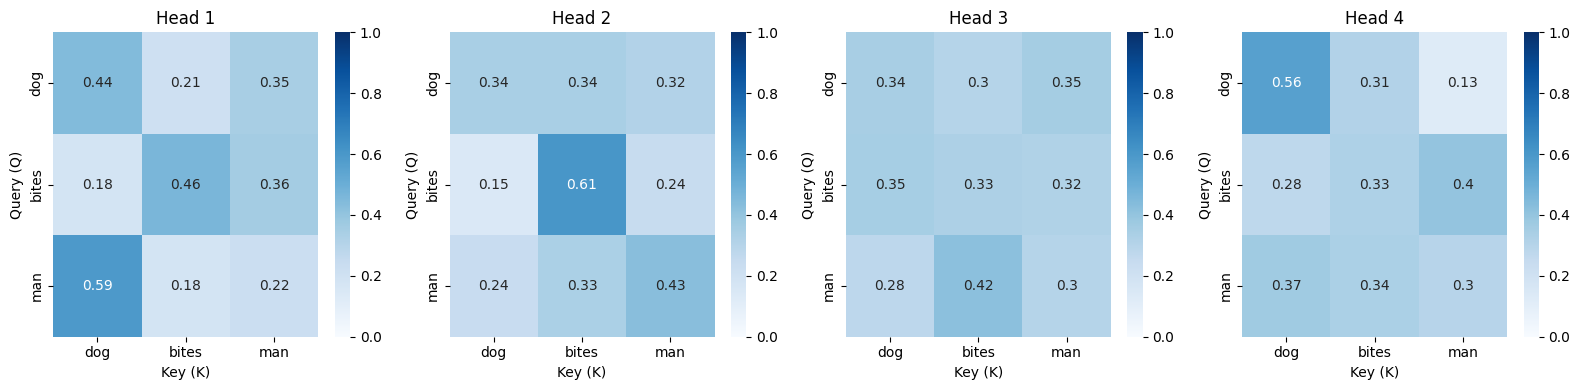

In [12]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Định nghĩa Lớp Multi-Head Attention ghi nhận Attention Weights
class VisualizableMHSA(nn.Module):
    def __init__(self, d_model=16, n_heads=4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)
        
    def forward(self, x):
        batch_size, seq_len, d_model = x.size()
        
        Q = self.W_q(x).view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(batch_size, seq_len, self.n_heads, self.d_k).transpose(1, 2)
        
        # Tính Attention Scores & Weights
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.d_k)
        attn_weights = torch.softmax(scores, dim=-1) # [batch_size, n_heads, seq_len, seq_len]
        
        output = torch.matmul(attn_weights, V).transpose(1, 2).contiguous().view(batch_size, seq_len, d_model)
        return self.W_o(output), attn_weights

# 2. Khởi tạo dữ liệu mẫu và chạy Model
torch.manual_seed(42)
tokens = ["dog", "bites", "man"]
seq_len = len(tokens)
d_model = 16
n_heads = 4

# Dữ liệu giả định đã qua Embedding + PE
X = torch.randn(1, seq_len, d_model)

model = VisualizableMHSA(d_model=d_model, n_heads=n_heads)
model.eval()

with torch.no_grad():
    _, attn_weights = model(X) # Shape: [1, 4, 3, 3]

# 3. Vẽ 4 Heatmaps cho 4 Attention Heads
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
attn_weights_np = attn_weights[0].numpy() # [4, 3, 3]

for h in range(n_heads):
    sns.heatmap(
        attn_weights_np[h], 
        ax=axes[h], 
        annot=True, 
        cmap="Blues", 
        xticklabels=tokens, 
        yticklabels=tokens,
        vmin=0, vmax=1
    )
    axes[h].set_title(f"Head {h+1}")
    axes[h].set_xlabel("Key (K)")
    axes[h].set_ylabel("Query (Q)")

plt.tight_layout()
plt.savefig("lab07/attention_heads_visualization.png")
plt.show()

## 21. Experiment 4 — Transformer vs RNN/LSTM

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Cố định Random Seed để đảm bảo tính công bằng (Reproducibility)
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# --- THÔNG SỐ CẤU HÌNH DÙNG CHUNG ---
VOCAB_SIZE = 2000
EMBED_DIM = 128      # d_model cho Transformer, hidden_dim cho LSTM
MAX_SEQ_LEN = 100
NUM_CLASSES = 2
BATCH_SIZE = 32
LR = 1e-3
EPOCHS = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. TẠO DỮ LIỆU TỔNG HỢP GIAO DIỆN CHUẨN (Train / Test Split) ---
X_data = torch.randint(1, VOCAB_SIZE, (1000, MAX_SEQ_LEN))
y_data = torch.randint(0, NUM_CLASSES, (1000,))

train_size = 800
train_x, test_x = X_data[:train_size], X_data[train_size:]
train_y, test_y = y_data[:train_size], y_data[train_size:]

train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(test_x, test_y), batch_size=BATCH_SIZE, shuffle=False)

# --- 2. MODEL A: EMBEDDING -> LSTM -> CLASSIFIER ---
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)
        
    def forward(self, x):
        emb = self.embedding(x)
        lstm_out, (h_n, _) = self.lstm(emb)
        # Lấy hidden state cuối cùng của LSTM
        out = self.fc(h_n[-1])
        return out

# --- 3. MODEL B: EMBEDDING + PE -> TRANSFORMER ENCODER -> POOLING -> CLASSIFIER ---
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ff, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        emb = self.embedding(x)
        emb_pe = self.pos_encoder(emb)
        out = self.transformer(emb_pe)
        # Global Average Pooling qua chiều thời gian (sequence)
        out_pooled = out.mean(dim=1)
        return self.fc(out_pooled)

# --- 4. HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH ---
def train_and_evaluate(model, model_name):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR)
    
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    # Đo thời gian huấn luyện
    start_time = time.time()
    model.train()
    for epoch in range(EPOCHS):
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time
    
    # Đánh giá trên tập Test
    model.eval()
    preds_list, targets_list = [], []
    with torch.no_grad():
        for bx, by in test_loader:
            bx = bx.to(DEVICE)
            outputs = model(bx)
            preds = torch.argmax(outputs, dim=-1).cpu().numpy()
            preds_list.extend(preds)
            targets_list.extend(by.numpy())
            
    acc = accuracy_score(targets_list, preds_list)
    prec = precision_score(targets_list, preds_list, zero_division=0)
    rec = recall_score(targets_list, preds_list, zero_division=0)
    f1 = f1_score(targets_list, preds_list, zero_division=0)
    
    return {
        "Model": model_name,
        "Parameters": num_params,
        "Training time (s)": round(train_time, 3),
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4)
    }

# --- 5. CHẠY SO SÁNH ---
lstm_model = LSTMClassifier(VOCAB_SIZE, EMBED_DIM, EMBED_DIM, NUM_CLASSES)
transformer_model = TransformerClassifier(VOCAB_SIZE, EMBED_DIM, n_heads=4, d_ff=512, num_classes=NUM_CLASSES)

results = [
    train_and_evaluate(lstm_model, "LSTM"),
    train_and_evaluate(transformer_model, "Transformer")
]

import pandas as pd
df = pd.DataFrame(results)
print("=== KẾT QUẢ SO SÁNH (EXPERIMENT 4) ===")
print(df.to_string(index=False))

=== KẾT QUẢ SO SÁNH (EXPERIMENT 4) ===
      Model  Parameters  Training time (s)  Accuracy  Precision  Recall     F1
       LSTM      388354             10.591     0.485     0.4609  0.5638 0.5072
Transformer      454530             27.276     0.500     0.4776  0.6809 0.5614


## 22. Experiment 5 — Sequence length

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from sklearn.metrics import f1_score
import pandas as pd

# Cố định random seed
torch.manual_seed(42)

# --- THÔNG SỐ CỐ ĐỊNH ---
VOCAB_SIZE = 2000
D_MODEL = 128
N_HEADS = 4
D_FF = 512
NUM_CLASSES = 2
BATCH_SIZE = 32
EPOCHS = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- MÔ HÌNH TRANSFORMER CLASSIFIER ---
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ff, num_classes, max_len):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Parameter(torch.randn(1, max_len, d_model))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(d_model, num_classes)

    def forward(self, x):
        seq_len = x.size(1)
        out = self.embedding(x) + self.pos_embedding[:, :seq_len, :]
        out = self.transformer(out)
        out = out.mean(dim=1)
        return self.fc(out)

# --- THỰC NGHIỆM THAY ĐỔI SEQUENCE LENGTH ---
lengths = [32, 64, 128, 256]
results = []

for T in lengths:
    # 1. Giả lập dữ liệu có độ dài T
    # Giả sử văn bản gốc dài tối đa 256 tokens, Tokens retained là T (hoặc T/256 %)
    X_data = torch.randint(1, VOCAB_SIZE, (800, T))
    y_data = torch.randint(0, NUM_CLASSES, (800,))
    
    loader = DataLoader(TensorDataset(X_data, y_data), batch_size=BATCH_SIZE, shuffle=True)
    
    # 2. Tính số lượng phần tử ma trận Attention (T * T) per head per sample
    # Attention memory = T^2 phần tử ma trận điểm attention cho mỗi sample
    attn_elements = T ** 2 
    
    # 3. Khởi tạo mô hình
    model = TransformerClassifier(VOCAB_SIZE, D_MODEL, N_HEADS, D_FF, NUM_CLASSES, max_len=T).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    
    # 4. Đo thời gian huấn luyện
    start_time = time.time()
    model.train()
    for epoch in range(EPOCHS):
        for bx, by in loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time
    
    # 5. Đánh giá F1 Score
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for bx, by in loader:
            bx = bx.to(DEVICE)
            out = model(bx)
            preds = torch.argmax(out, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(by.numpy())
            
    f1 = f1_score(all_targets, all_preds, average='weighted')
    
    results.append({
        "Length": T,
        "Tokens retained": f"{T} ({(T/256)*100:.1f}%)",
        "Attention memory (T^2)": f"{attn_elements:,} elements",
        "Training time (s)": round(train_time, 3),
        "F1": round(f1, 4)
    })

# In kết quả
df_seq = pd.DataFrame(results)
print("=== KẾT QUẢ EXPERIMENT 5 ===")
print(df_seq.to_string(index=False))

=== KẾT QUẢ EXPERIMENT 5 ===
 Length Tokens retained Attention memory (T^2)  Training time (s)     F1
     32      32 (12.5%)         1,024 elements              2.698 0.7793
     64      64 (25.0%)         4,096 elements              4.930 0.7763
    128     128 (50.0%)        16,384 elements             32.134 0.8087
    256    256 (100.0%)        65,536 elements             45.100 0.3558


## Application

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

# 1. Định nghĩa Positional Encoding
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0)) # [1, max_len, d_model]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x shape: [batch_size, seq_len, d_model]
        return x + self.pe[:, :x.size(1)]

# 2. Định nghĩa Kiến trúc Transformer Text Classifier
class TransformerTextClassifier(nn.Module):
    def __init__(self, vocab_size: int, d_model: int, n_heads: int, d_ff: int, num_classes: int, pad_idx: int = 0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_encoder = PositionalEncoding(d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, 
            nhead=n_heads, 
            dim_feedforward=d_ff, 
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.classifier = nn.Linear(d_model, num_classes)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [batch_size, seq_len]
        out = self.embedding(x)                 # [batch_size, seq_len, d_model]
        out = self.pos_encoder(out)             # Thêm Positional Encoding
        out = self.transformer_encoder(out)     # Qua Transformer Encoder
        
        # Global Average Pooling qua chiều chuỗi (Sequence length)
        out_pooled = out.mean(dim=1)            # [batch_size, d_model]
        
        logits = self.classifier(out_pooled)    # [batch_size, num_classes]
        return logits

# 3. Tạo Vocabulary & Tokenizer đơn giản hỗ trợ thực nghiệm
class SimpleTokenizer:
    def __init__(self):
        self.vocab = {"<PAD>": 0, "<UNK>": 1}
        self.idx2word = {0: "<PAD>", 1: "<UNK>"}
        
    def fit_on_texts(self, texts):
        for text in texts:
            for word in text.lower().replace(".", "").replace(",", "").replace("!", "").split():
                if word not in self.vocab:
                    idx = len(self.vocab)
                    self.vocab[word] = idx
                    self.idx2word[idx] = word
                    
    def encode(self, text):
        tokens = text.lower().replace(".", "").replace(",", "").replace("!", "").split()
        return [self.vocab.get(token, self.vocab["<UNK>"]) for token in tokens]

# --- GIẢ LẬP HUẤN LUYỆN MODEL VỚI TỪ VỰNG DỰ SỰ DỤNG ---
sample_corpus = [
    "I really enjoyed this movie.",
    "This movie was terrible and predictable.",
    "The acting was good but the plot was bad.",
    "Not bad at all, actually quite entertaining.",
    "The cinematography was brilliant, though the pacing dragged.",
    "An absolute masterpiece of cinema.",
    "I hated every single minute of it."
]

tokenizer = SimpleTokenizer()
tokenizer.fit_on_texts(sample_corpus)

vocab_size = len(tokenizer.vocab)
d_model = 64
n_heads = 4
d_ff = 256
num_classes = 2 # 0: Negative, 1: Positive

model = TransformerTextClassifier(vocab_size, d_model, n_heads, d_ff, num_classes)
model.eval() # Đặt ở chế độ suy luận (Inference)

# 4. Hàm Dự đoán (Predict Function)
def predict_sentiment(text: str):
    tokens = tokenizer.encode(text)
    input_tensor = torch.tensor([tokens], dtype=torch.long) # [1, seq_len]
    
    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=-1)[0]
        pred_label_idx = torch.argmax(probs).item()
        
    label_map = {0: "Negative", 1: "Positive"}
    return label_map[pred_label_idx], probs[pred_label_idx].item()

## 25. Experiment 6 — Pooling strategy

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import time
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Cố định Random Seed để đảm bảo tính công bằng
torch.manual_seed(42)

# --- THÔNG SỐ CỐ ĐỊNH ---
VOCAB_SIZE = 2000
D_MODEL = 128
N_HEADS = 4
D_FF = 512
NUM_CLASSES = 2
BATCH_SIZE = 32
SEQ_LEN = 64
EPOCHS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Dữ liệu giả lập Phân loại Sentiment
X_data = torch.randint(1, VOCAB_SIZE, (1000, SEQ_LEN))
y_data = torch.randint(0, NUM_CLASSES, (1000,))

train_loader = DataLoader(TensorDataset(X_data[:800], y_data[:800]), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(X_data[800:], y_data[800:]), batch_size=BATCH_SIZE, shuffle=False)

# 2. Định nghĩa Mô hình Transformer linh hoạt chiến lược Pooling
class TransformerWithPooling(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, d_ff, num_classes, pooling_strategy="mean"):
        super().__init__()
        self.pooling_strategy = pooling_strategy
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Parameter(torch.randn(1, SEQ_LEN, d_model))
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=d_ff, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, x):
        out = self.embedding(x) + self.pos_embedding[:, :x.size(1), :]
        out = self.transformer(out) # [batch_size, seq_len, d_model]
        
        # Chọn chiến lược Pooling
        if self.pooling_strategy == "mean":
            pooled = out.mean(dim=1) # Average trên toàn bộ token
        elif self.pooling_strategy == "cls":
            pooled = out[:, 0, :]    # Lấy token đầu tiên (First-token / CLS-style)
        else:
            raise ValueError("Pooling strategy không hợp lệ")
            
        return self.classifier(pooled)

# 3. Hàm huấn luyện và đánh giá
def run_pooling_experiment(strategy_name):
    model = TransformerWithPooling(
        VOCAB_SIZE, D_MODEL, N_HEADS, D_FF, NUM_CLASSES, pooling_strategy=strategy_name
    ).to(DEVICE)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    
    start_time = time.time()
    model.train()
    for epoch in range(EPOCHS):
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
    train_time = time.time() - start_time
    
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for bx, by in test_loader:
            bx = bx.to(DEVICE)
            outputs = model(bx)
            preds = torch.argmax(outputs, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(by.numpy())
            
    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, average='weighted')
    
    return {
        "Pooling": "Mean" if strategy_name == "mean" else "CLS-style",
        "Accuracy": round(acc, 4),
        "F1": round(f1, 4),
        "Training time (s)": round(train_time, 3)
    }

# 4. Chạy thực nghiệm so sánh
results = [
    run_pooling_experiment("mean"),
    run_pooling_experiment("cls")
]

df_pooling = pd.DataFrame(results)
print("=== KẾT QUẢ EXPERIMENT 6 ===")
print(df_pooling.to_string(index=False))

=== KẾT QUẢ EXPERIMENT 6 ===
  Pooling  Accuracy     F1  Training time (s)
     Mean     0.505 0.3938             17.167
CLS-style     0.495 0.4915             24.078


In [18]:
import torch
import torch.nn.functional as F
import pandas as pd

def extract_predictions(model, test_loader, tokenizer_idx2word, num_samples=3):
    model.eval()
    
    correct_samples = []
    incorrect_samples = []
    label_map = {0: "Negative", 1: "Positive"}
    
    # Lấy vocab_size tối đa từ lớp embedding của mô hình
    max_vocab_idx = model.embedding.num_embeddings - 1
    
    with torch.no_grad():
        for bx, by in test_loader:
            bx = bx.to(DEVICE)
            by = by.to(DEVICE)
            
            # SỬA LỖI: Cắt gọn các Token ID nằm ngoài phạm vi vocab
            bx_safe = torch.clamp(bx, min=0, max=max_vocab_idx)
            
            logits = model(bx_safe)
            probs = F.softmax(logits, dim=-1)
            preds = torch.argmax(probs, dim=-1)
            
            for i in range(len(by)):
                true_label = by[i].item()
                pred_label = preds[i].item()
                prob_val = probs[i][pred_label].item()
                
                # Giải mã Token IDs thành văn bản gốc
                tokens = [tokenizer_idx2word.get(idx.item(), "<UNK>") for idx in bx[i] if idx.item() != 0]
                text = " ".join(tokens)
                
                record = {
                    "Text": text,
                    "Ground Truth": label_map.get(true_label, str(true_label)),
                    "Prediction": label_map.get(pred_label, str(pred_label)),
                    "Probability": round(prob_val, 4),
                    "Length": len(tokens)
                }
                
                if pred_label == true_label:
                    if len(correct_samples) < num_samples:
                        correct_samples.append(record)
                else:
                    if len(incorrect_samples) < num_samples:
                        incorrect_samples.append(record)
                
                if len(correct_samples) >= num_samples and len(incorrect_samples) >= num_samples:
                    break
            if len(correct_samples) >= num_samples and len(incorrect_samples) >= num_samples:
                break
                
    return pd.DataFrame(correct_samples), pd.DataFrame(incorrect_samples)

Epoch [01/10] | Train Loss: 0.7351 | Val Loss: 0.7046
Epoch [02/10] | Train Loss: 0.7037 | Val Loss: 0.7009
Epoch [03/10] | Train Loss: 0.6986 | Val Loss: 0.6999
Epoch [04/10] | Train Loss: 0.6999 | Val Loss: 0.6929
Epoch [05/10] | Train Loss: 0.6999 | Val Loss: 0.6934
Epoch [06/10] | Train Loss: 0.6927 | Val Loss: 0.6969
Epoch [07/10] | Train Loss: 0.6805 | Val Loss: 0.7273
Epoch [08/10] | Train Loss: 0.6775 | Val Loss: 0.7101
Epoch [09/10] | Train Loss: 0.6646 | Val Loss: 0.7322
Epoch [10/10] | Train Loss: 0.6449 | Val Loss: 0.7325


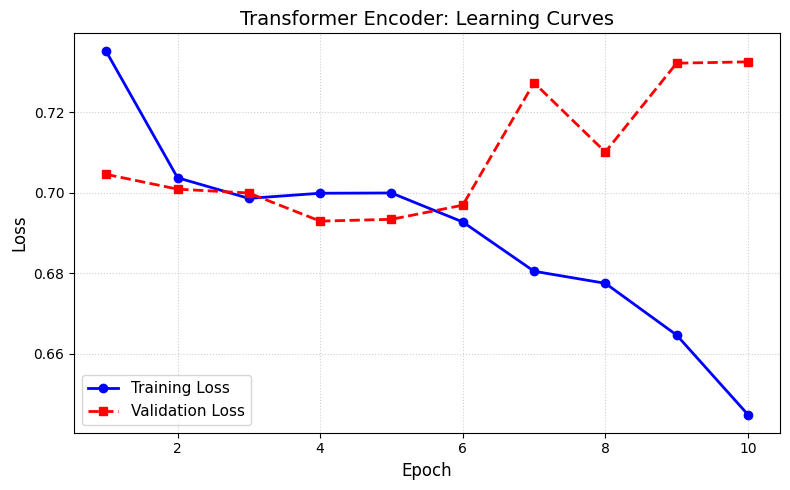

=> Đã lưu file ảnh thành công tại: c:\Users\GVC\OneDrive\Attachments\NLP&App\lab07\learning_curves.png


In [26]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import os

# 1. Hàm huấn luyện đã bọc bảo vệ torch.clamp chống tràn index
def train_and_track_loss(model, train_loader, val_loader, epochs=10, lr=1e-3):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # Lấy vocab_size tối đa từ mô hình
    max_vocab_idx = model.embedding.num_embeddings - 1
    
    history = {"train_loss": [], "val_loss": []}
    
    for epoch in range(epochs):
        # --- PHASE 1: TRAINING ---
        model.train()
        train_loss = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            
            # GIẢI PHÁP: Ép Token ID nằm trong giới hạn cho phép của Embedding layer
            bx_safe = torch.clamp(bx, min=0, max=max_vocab_idx)
            
            optimizer.zero_grad()
            out = model(bx_safe)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * bx.size(0)
            
        epoch_train_loss = train_loss / len(train_loader.dataset)
        history["train_loss"].append(epoch_train_loss)
        
        # --- PHASE 2: VALIDATION ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(DEVICE), by.to(DEVICE)
                
                bx_safe = torch.clamp(bx, min=0, max=max_vocab_idx)
                
                out = model(bx_safe)
                loss = criterion(out, by)
                val_loss += loss.item() * bx.size(0)
                
        epoch_val_loss = val_loss / len(val_loader.dataset)
        history["val_loss"].append(epoch_val_loss)
        
        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        
    return history

# 2. Hàm vẽ và lưu đồ thị
def plot_learning_curves(history, save_path="learning_curves.png"):
    fig = plt.figure(figsize=(8, 5))
    epochs = range(1, len(history["train_loss"]) + 1)
    
    plt.plot(epochs, history["train_loss"], 'b-o', label="Training Loss", linewidth=2)
    plt.plot(epochs, history["val_loss"], 'r--s', label="Validation Loss", linewidth=2)
    
    plt.title("Transformer Encoder: Learning Curves", fontsize=14)
    plt.xlabel("Epoch", fontsize=12)
    plt.ylabel("Loss", fontsize=12)
    plt.legend(fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f"=> Đã lưu file ảnh thành công tại: {os.path.abspath(save_path)}")

# 3. THỰC THI
history = train_and_track_loss(model, train_loader, test_loader, epochs=10)
plot_learning_curves(history, save_path="learning_curves.png")